# Simulação

Use fp = 80 Hz, fr = 150 Hz, fs = 1000 Hz, Ap = 1 dB e Ar = 40 dB; procure um comprimento FIR Hamming suficiente e compare três famílias IIR.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


,Método,Ordem,Mult./am.,Ripple (dB),Atenuação (dB)
0,FIR Hamming,44,45,0.077623,43.326879
1,butter,8,17,0.997500,41.760124
2,cheby1,5,11,1.000000,44.918219
3,cheby2,5,11,0.998121,40.000000
4,ellip,4,9,1.000000,40.000000


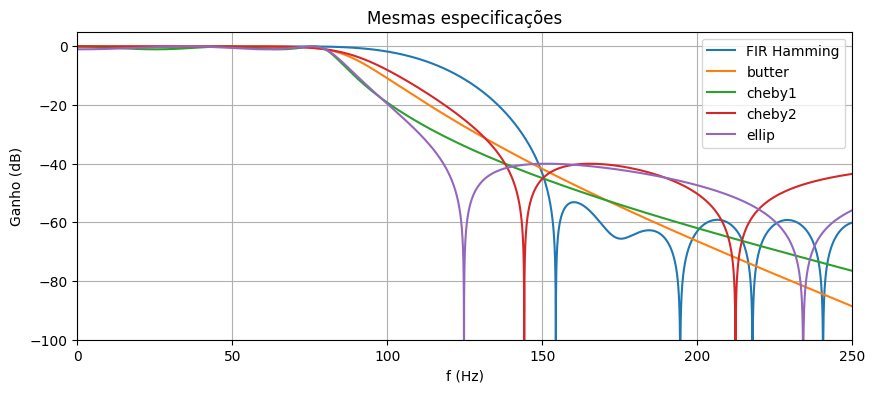

In [2]:
fs=1000; linhas=[]
for L in range(11,402,2):
    b=signal.firwin(L,115,fs=fs); f,H=signal.freqz(b,worN=32768,fs=fs); db=20*np.log10(np.maximum(abs(H),1e-15))
    if db[f<=80].min()>=-1 and db[f<=80].max()<=1 and db[f>=150].max()<=-40: break
filtros=[('FIR Hamming',b,np.array([1.]))]
for familia in ['butter','cheby1','cheby2','ellip']:
    bi,ai=signal.iirdesign(80,150,1,40,fs=fs,ftype=familia); filtros.append((familia,bi,ai))
for nome,b,a in filtros:
    f,H=signal.freqz(b,a,worN=32768,fs=fs); db=20*np.log10(np.maximum(abs(H),1e-15)); pb=db[f<=80]; ar=-db[f>=150].max()
    linhas.append([nome,max(len(b),len(a))-1,len(b)+len(a)-1,pb.max()-pb.min(),ar])
    plt.plot(f,db,label=nome)
display(pd.DataFrame(linhas,columns=['Método','Ordem','Mult./am.','Ripple (dB)','Atenuação (dB)']))
plt.xlim(0,250); plt.ylim(-100,5); plt.xlabel('f (Hz)'); plt.ylabel('Ganho (dB)'); plt.title('Mesmas especificações'); plt.legend(); plt.show()